In [6]:
# BookBeacon – Goodreads Data Exploration 

# Phase 1: Raw Data Inspection 

# This notebook explores the raw Goodreads review dataset before any cleaning or transformation.

### Goals
# - Understand the dataset structure and schema
# - Verify the fields available for BookBeacon
# - Inspect data types and missing values
# - Identify potential data quality issues
# - Determine appropriate cleaning and filtering rules

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path 

In [8]:
DATA_PATH = Path("../data/raw/goodreads_reviews_poetry.json")

print(DATA_PATH)
print("File exists:", DATA_PATH.exists())

../data/raw/goodreads_reviews_poetry.json
File exists: True


In [9]:
sample = pd.read_json(
    DATA_PATH,
    lines = True,
    nrows = 5
)

In [10]:
sample

,user_id,book_id,review_id,rating,review_text,date_added,date_updated,read_at,started_at,n_votes,n_comments
0,3ca7375dba942a760e53b726c472a7dd,402128,28423ff309bc896c071a8d9df4a10e8a,5,I have three younger siblings and we grew up w...,Tue Jun 12 08:59:04 -0700 2012,Fri Jun 15 11:41:12 -0700 2012,,NaT,0,0
1,0ef32090550901ead25cb0ea21c4d36b,92270,2db1180992e2b0b1631a3ac5644bde84,5,This is my favorite collection of poetry.,Mon Apr 14 18:42:40 -0700 2014,Mon Apr 14 18:43:05 -0700 2014,Wed Jan 01 00:00:00 -0800 1997,NaT,0,0
2,0ef32090550901ead25cb0ea21c4d36b,908708,bca57fa40e92c9261b00b03dbebd96fe,4,"He's so disturbing. So very, very disturbing.",Tue Apr 22 13:58:10 -0700 2008,Tue Apr 22 13:58:33 -0700 2008,,NaT,0,0
3,d37b46b2190ed7c518259f29b47a9b36,253264,cb1ebc02d8b2aff15735d513877463ce,5,I just reread this play for a class I am takin...,Wed Sep 27 19:08:08 -0700 2017,Sat Sep 30 06:39:45 -0700 2017,Wed Sep 27 00:00:00 -0700 2017,2017-09-26 00:00:00-07:00,1,0
4,af157d0205b8a901dee6d4a2aed7e6ad,70885,8dca128b8e869048a7442c18659dbece,5,"Cuanto mas leo, mas me gusta. Su poesia es env...",Thu Jun 18 20:00:03 -0700 2015,Thu Jun 18 20:01:29 -0700 2015,Thu Jun 18 00:00:00 -0700 2015,2015-06-16 00:00:00-07:00,0,0


### Initial Observations

#### Dataset Structure
- The dataset contains user IDs, book IDs, ratings, and written review text, which are primary fields needed for BookBeacon.
- `user_id`: anonymous identifier for a user.
- `book_id`: identifier for a book.
- `review_id`: identifier for a review.
- Some `user_id` values appear multiple times, suggesting users can have multiple book reviews.

#### Review Text
- Review length and detail vary substantially. Some reviews are descriptive, while others contain only short remarks.
- At least one review in the initial sample is written in Spanish, suggesting the dataset may contain multilingual review text.
- One user described a book as "disturbing" while still assigning it 4 stars. This suggests that the apparent sentiment of review text may not directly correspond to the numeric rating.
- Written reviews may contain preference information that is not captured by star ratings alone.

#### Dates
- Several `started_at` values are missing (`NaT`) in the initial sample.
- Some `read_at` dates are much earlier than the corresponding `date_added`; one sampled book was marked as read in 1997 but added to Goodreads in 2014.
- The displayed `read_at` and `started_at` timestamps use `00:00:00`, which may indicate that only the date, rather than the exact time, is meaningful.

### Questions to Investigate

- How frequently do the same users appear in the dataset, and how many books does each user typically review?
- What proportion of `started_at` and `read_at` values are missing?
- Are there records where `started_at` occurs after `read_at`?
- What is the relationship between `date_added`, `date_updated`, `started_at`, and `read_at`?
- What does `-0700` represent in the Goodreads timestamps?
- Is `book_id` a Goodreads identifier or an identifier created specifically for this dataset?
- How common are non-English reviews?
- How much does review length vary?
- Do `n_votes` or `n_comments` provide useful information for BookBeacon, or should they eventually be excluded?
- Could review votes provide a useful signal of review quality, or would incorporating them introduce popularity/visibility bias?

## Full Dataset Profiling

Now that the raw schema has been inspected using a small sample, the next step is to profile the full dataset and quantify its structure, missingness, and basic data quality characteristics.

In [11]:
df = pd.read_json(
    DATA_PATH,
    lines = True
)

print("Dataset loaded.")

Dataset loaded.


In [12]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 154,555
Columns: 11


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 154555 entries, 0 to 154554
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       154555 non-null  str  
 1   book_id       154555 non-null  int64
 2   review_id     154555 non-null  str  
 3   rating        154555 non-null  int64
 4   review_text   154555 non-null  str  
 5   date_added    154555 non-null  str  
 6   date_updated  154555 non-null  str  
 7   read_at       154555 non-null  str  
 8   started_at    154555 non-null  str  
 9   n_votes       154555 non-null  int64
 10  n_comments    154555 non-null  int64
dtypes: int64(4), str(7)
memory usage: 13.0 MB


In [14]:
n_users = df["user_id"].nunique()
n_book = df["book_id"].nunique()
n_reviews = df["review_id"].nunique()

print(f"Unique users: {n_users:,}")
print(f"Unique books: {n_book:,}")
print(f"Unique reviews: {n_reviews:,}")

Unique users: 47,400
Unique books: 36,412
Unique reviews: 154,555


- All 154,555 reviews have unique `review_id` values, indicating there are no duplicate review IDs in the dataset.

In [15]:
repeated_user_book = df.duplicated(
    subset = ["user_id", "book_id"],
    keep = False
)

print(f"Rows involved in repeated user-book pairs: {repeated_user_book.sum():,}")

Rows involved in repeated user-book pairs: 0


- All 154,555 records have unique `review_id` values.
- No repeated `(user_id, book_id)` pairs were found, meaning each user has at most one review record for a given book in this dataset.

In [16]:
missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_count, "missing_percent": missing_percent
})

missing_summary.sort_values("missing_percent", ascending = False)

,missing_count,missing_percent
user_id,0,0.0
book_id,0,0.0
review_id,0,0.0
rating,0,0.0
review_text,0,0.0
date_added,0,0.0
date_updated,0,0.0
read_at,0,0.0
started_at,0,0.0
n_votes,0,0.0


In [17]:
empty_count = (df == "").sum()
empty_percent = ((df == "").mean() * 100).round(2)

empty_summary = pd.DataFrame({
    "empty_count": empty_count,
    "empty_percent": empty_percent
})

empty_summary.sort_values(
    "empty_count",
    ascending=False
).style.format({
    "empty_count": "{:,}",
    "empty_percent": "{:.2f}%"
})

,empty_count,empty_percent
started_at,"77,259",49.99%
read_at,"35,085",22.70%
review_text,163,0.11%
user_id,0,0.00%
book_id,0,0.00%
review_id,0,0.00%
rating,0,0.00%
date_added,0,0.00%
date_updated,0,0.00%
n_votes,0,0.00%


Missing-Value Analysis: Interpretation
- The initial df.isna() check reported no missing values. However, further investigation revealed that some missing information is represented as empty strings ("")
- Reading dates: started_at is empty for 77,259 records (49.99%), while read_at is empty for 35,085 records (22.7%). Because nearly half the records lack a readings start date, analyses or features that depend on started_at would have limited coverage and could introduce selection bias. This field is not currently necessary for BookBeacon's primary rating-behavior research, so missing start dates alone should not be ground for excluding records. 
- Reviw text: Only 163 records (0.11%) have blank review_text, including after checking for whitespace-only reviews. Approximately 99.89% of records contain nonempty text, which is promosing for future NLP experiments. However, the usefulness, language, and informativeness of these reviews have not yet been evaluated.
- Potential Handling: Records without review text may still be useful for ratings-based analysis and recommendation. They may need to be excluded from experiments requiring review text, but no records will be removed at this stage.
- Next questions: How informative are the nonempty reviews? How much does review length vary? Do missing reading dates differ systematically across users or rating groups? Could a user's rating standards change over time? How well do older ratings represent a user's current preferences? Is reading duration associated with differences in ratings or review characteristics? 

In [18]:
blank_reviews = df["review_text"].str.strip().eq("").sum()

print(f"Blank review texts: {blank_reviews:,}")

Blank review texts: 163


- After stripping whitespace, the blank review count remained 163. No additional whitespace-only reviews were found. 

## Rating Validation
Before analyzing user rating behavior, inspect the values in the `rating` column to identify valid ratings, possible unrated records, and the overall rating distribution.

In [19]:
df["rating"].value_counts().sort_index()

rating
0     6732
1     4077
2     9942
3    28028
4    47266
5    58510
Name: count, dtype: int64

- There are 6732 reviews with 0 star ratings. This is likely an encoding for no star rating provided, need to verify this.

In [20]:
print("Rating data type: ", df["rating"].dtype)
print("Unique rating values: ", sorted(df["rating"].unique()))

Rating data type:  int64
Unique rating values:  [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


- Confirms that the only values present are 0, 1, 2, 3, 4, and 5. There are no unexpected values such as -1, 6, or "five"

Rating Validation: Initial Findings 
- The rating columns contains integer values ranging from 0 to 5, with no unexpected values outside this range
- Five-star ratings are the most common (58,510 records), followed by four-star ratings (47,266). This suggests that the observed ratings distribution is concentrated toward the higher end of the scale.
- There are also 6,732 records with rating = 0. Since Goodreads uses a 1-5 star scale, zero likely represents a missing or unassigned star rating rather than a negative opinion. This interpretation should be confirmed against the dataset documentation beofre defining a cleaning rule. 
- Questions to investigate: Are users more likely to record a rating when they love a book than when they dislike it? Are most five-star ratings coming from users who predominantly give four and five-star ratings?

In [21]:
rating_count = df["rating"].value_counts().sort_index()

rating_percent = (df["rating"].value_counts(normalize = True).sort_index() * 100).round(2)

rating_summary = pd.DataFrame({"count": rating_count, "percent": rating_percent})

rating_summary

,count,percent
rating,,
0,6732,4.36
1,4077,2.64
2,9942,6.43
3,28028,18.13
4,47266,30.58
5,58510,37.86


- Four and five-star ratings make up 68.44% of all records, confirming that the observed distribution is concentrated toward higher ratings. This does not yet tell us whether most users rate highly or whether a smaller group of active users contributes disproportionately to these ratings.

In [22]:
reviews_per_user = df["user_id"].value_counts()
reviews_per_user.describe()

count    47400.000000
mean         3.260654
std         10.134977
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       1095.000000
Name: count, dtype: float64

The dataset contains 47,400 users, with a median of one review per user and a maximum of 1,095. User activity is highly unever. This matters because highly active users contribute more to the overall rating distribution, while users with very few reviews provide insufficient evidence for estimating their individual rating tendencies/

In [23]:
for threshold in [2, 5, 10, 20]:
    user_count = (reviews_per_user >= threshold).sum()
    print(f"Users with at least {threshold} reviews: {user_count:,}")

Users with at least 2 reviews: 20,305
Users with at least 5 reviews: 6,542
Users with at least 10 reviews: 2,692
Users with at least 20 reviews: 995


- Of the 47,400 users, 27,095 have only one record, while 2,692 have at least 10 records. Most user therefore have limited history in this poetry subset, which may make individual rating tendencies difficult to estimate reliably. These counts include records with rating = 0, so the number of usable star ratings per user still needs to be examined

In [24]:
rated_df = df[df["rating"].between(1, 5)].copy()

ratings_per_user = rated_df["user_id"].value_counts()

ratings_per_user.describe()

count    45733.000000
mean         3.232305
std         10.073227
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       1095.000000
Name: count, dtype: float64

- After restricting the data to ratings from 1-5, the number of users decreases from 47,400 to 45,733 while the median remains one rating per user. This indicates that limited user history remains a challenge for estimating individual rating behavior 

In [25]:
for threshold in [2, 5, 10, 20]:
    user_count = (ratings_per_user >= threshold).sum()
    print(f"Users with at least {threshold} ratings: {user_count:,}")

Users with at least 2 ratings: 19,508
Users with at least 5 ratings: 6,243
Users with at least 10 ratings: 2,550
Users with at least 20 ratings: 945


After excluding zero ratings, 2,550 users have at least 10 valid star ratings. This provides a potential group of investigatng individual rating behavior, although most users have much less history.

In [26]:
user_mean_rating = rated_df.groupby("user_id")["rating"].mean()

user_mean_rating.describe()

count    45733.000000
mean         4.070133
std          0.943628
min          1.000000
25%          3.500000
50%          4.000000
75%          5.000000
max          5.000000
Name: rating, dtype: float64

- At least a quarter of users have an average of exactly 5 starts. The average rating per user is 4.07 with a standard deviation of 0.94 (there is a good amount of variation).

In [27]:
users_with_10_ratings = ratings_per_user[ratings_per_user >= 10].index

experienced_user_means = user_mean_rating.loc[users_with_10_ratings]

experienced_user_means.describe()

count    2550.000000
mean        3.921560
std         0.554338
min         1.600000
25%         3.538462
50%         3.937500
75%         4.320000
max         5.000000
Name: rating, dtype: float64

- The standard deviation dropped from 0.94 to 0.55 stars. Therefore the averages of users with at least 10 ratings are less spread out. This is consistent with the idea that single-rating users contributed to some of the extreme averages in the original analysis.
- The mean dropped from 4.07 to 3.92. The average users personal averages is slightly lower in te group with more rating history. This supports investigating whether users with very little history are disproportionately represented in high ratings. It doesn't establish why that pattern occurs. 
- There is still variation among users with more history. The middle 50% of these users have average ratings between approximately 3.54 and 4.32.


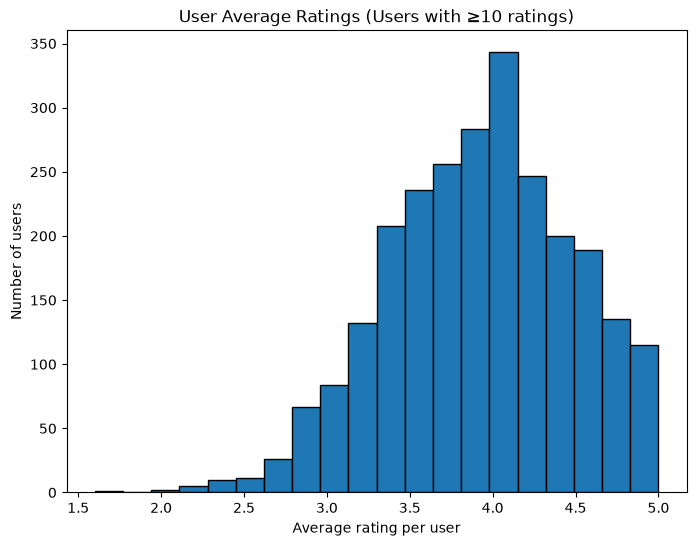

In [28]:
plt.figure(figsize = (8, 6))

plt.hist(experienced_user_means, bins = 20, edgecolor = "black")

plt.xlabel("Average rating per user")
plt.ylabel("Number of users")
plt.title("User Average Ratings (Users with ≥10 ratings)")

plt.show()

### Proportion of High Ratings per User

- Investigate whether users with sufficient rating history predominantly assign four and five-star ratings. 

In [29]:
high_rating_share = (
    rated_df["rating"].ge(4).groupby(rated_df["user_id"]).mean() * 100
)

high_rating_share.loc[users_with_10_ratings].describe()

count    2550.000000
mean       69.107435
std        21.969550
min         0.000000
25%        53.846154
50%        72.222222
75%        86.666667
max       100.000000
Name: rating, dtype: float64

- Among users with at least 10 valid ratings, the average user gives four or five stars to 69.11% of the books they have rated in this poetry subset
- The median was 72.22%, indicating that high ratings are common at the individual-user level, not just in the overall rating distirbution. 
- However, high-rating percentages vary across users (standard deviation: 21.97%)

In [30]:
user_stats = rated_df.groupby("user_id")["rating"].agg(
    rating_count="count",
    mean_rating="mean",
)

user_stats.head()

,rating_count,mean_rating
user_id,,
000192962b87d560f00b06fdcbd71681,1,5.0
0004ae25e3cf5f5a44b6f1ccfdd3d343,3,5.0
0006260f85929db85eddee3a0bd0e504,1,4.0
0006a5b8cda1ba6d7b911dc575f6547b,4,2.5
00098165da6612b8b26d453fd19bb754,4,3.0


User Rating Counts and Means

- In the first five rows, two users have an average of 5 stars, but one has only one rating while the other has three. A high average based on one rating tells us little about a user's usual rating behavior.
- The other users shown have averages of 4.0, 2.5, and 3.0 stars. These are only five users, so this preview does not tell us how common these patterns are across the dataset.

In [32]:
user_stats["rating_activity_group"] = pd.cut(
    user_stats["rating_count"],
    bins=[0, 1, 4, 9, 19, float("inf")],
    labels=["1", "2–4", "5–9", "10–19", "20+"],
)

activity_summary = user_stats.groupby("rating_activity_group", observed=False).agg(
    user_count=("rating_count", "size"),
    mean_user_rating=("mean_rating", "mean"),
)

activity_summary.round(3)

,user_count,mean_user_rating
rating_activity_group,,
1,26225,4.114
2–4,13265,4.040
5–9,3693,3.969
10–19,1605,3.933
20+,945,3.902


- Users with one valid rating have an average of 4.11 stars, compared with 3.90 stars for users with 20 or more. The group averages decrease as rating history increases in this poetry subset.
- Each user counts equally in these averages, regardless of how many ratings they contributed. Activity refers only to valid ratings in this subset.
- This shows an association, not an explanation: differences in book choices, which books users choose to review, or rating habits could all contribute.

In [ ]:
rating_contributions = rated_df.assign(
    rating_activity_group=rated_df["user_id"].map(user_stats["rating_activity_group"]),
    is_high_rating=rated_df["rating"].ge(4),
)

group_contributions = rating_contributions.groupby(
    "rating_activity_group", observed=False
).agg(
    user_count=("user_id", "nunique"),
    rating_count=("rating", "size"),
    high_rating_count=("is_high_rating", "sum"),
)

group_contributions["user_share_pct"] = (
    group_contributions["user_count"] / group_contributions["user_count"].sum() * 100
)
group_contributions["rating_share_pct"] = (
    group_contributions["rating_count"] / group_contributions["rating_count"].sum() * 100
)
group_contributions["high_rating_share_pct"] = (
    group_contributions["high_rating_count"]
    / group_contributions["high_rating_count"].sum() * 100
)

group_contributions.round(2)

,user_count,rating_count,high_rating_count,user_share_pct,rating_share_pct,high_rating_share_pct
rating_activity_group,,,,,,
1,26225,26225,19811,57.34,17.74,18.73
2–4,13265,34135,25032,29.01,23.09,23.67
5–9,3693,23644,16704,8.08,15.99,15.79
10–19,1605,21184,14742,3.51,14.33,13.94
20+,945,42635,29487,2.07,28.84,27.88


- Users with 20+ valid ratings make up 2.07% of rated users but contribute 28.84% of all valid ratings and 27.88% of all four- and five-star ratings. A small group of active users therefore contributes a large share of the high ratings.
- Their share of high ratings is slightly lower than their share of all valid ratings. Their large contribution reflects how many ratings they provide; it does not mean they are more likely to give high ratings.
- Each percentage column has its own denominator: all rated users, all valid ratings, or all four- and five-star ratings. The high-rating share is not the percentage of ratings within a group that are high.

### Variation Within Users’ Ratings

In [ ]:
user_rating_spread = rated_df.groupby("user_id")["rating"].agg(
    rating_count="count",
    rating_std="std",
)

experienced_user_spread = user_rating_spread.loc[
    user_rating_spread["rating_count"].ge(10), "rating_std"
]

experienced_user_spread.describe().round(3)

count    2550.000
mean        0.864
std         0.300
min         0.000
25%         0.675
50%         0.863
75%         1.060
max         1.776

- Among the 2,550 users with at least 10 valid ratings, the median within-user standard deviation is about 0.86 stars. This means the users ratings are staying relativly consistent, not much variation. 
- The middle half of users have standard deviations between about 0.67 and 1.06 stars. A value of zero means the user gave the same star rating to every book they rated in this subset.
- This differs from our earlier comparison of user averages: here we measure variation within each user's ratings. Differences could reflect their book choices or experiences as well as rating habits; they do not establish differences in how users interpret the scale. Ten ratings is a working cutoff, not a guarantee of a stable estimate.

In [ ]:
user_star_percentages = (
    pd.crosstab(rated_df["user_id"], rated_df["rating"], normalize="index")
    .reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
    * 100
)

experienced_star_percentages = user_star_percentages.loc[users_with_10_ratings]

mean_star_percentages = experienced_star_percentages.mean().rename(
    "mean_user_percentage"
)
mean_star_percentages.round(2)

rating
1     2.67
2     7.31
3    20.92
4    33.42
5    35.69

- Among users with at least 10 valid ratings, the average user gives 1 star to 2.67% of their rated books, 2 stars to 7.31%, 3 stars to 20.92%, 4 stars to 33.42%, and 5 stars to 35.69%.
- Each user has equal weight: we calculate their own percentages first, then average across users. These are group averages, not a pattern every user follows.
- The 4- and 5-star percentages add up to 69.11%, matching our earlier high-rating-share result for this same group. This breaks that result down across all five star values.